# Tracking Analysis — Third Parties and Tracker Detection

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from utils import parse_har_files_to_dataframe
from common import BASE_HAR_DIR


sns.set_theme(style="whitegrid", context="paper")
pd.set_option('display.max_colwidth', 128)

# use_cache=False forces reading from BASE_HAR_DIR and prints how many folders/HAR files were found
df = parse_har_files_to_dataframe(BASE_HAR_DIR, test=False, use_cache=True)


### Tracker domains vs third parties
- Ensure most tracker domains are third-party domains


<Axes: xlabel='is_tracker'>

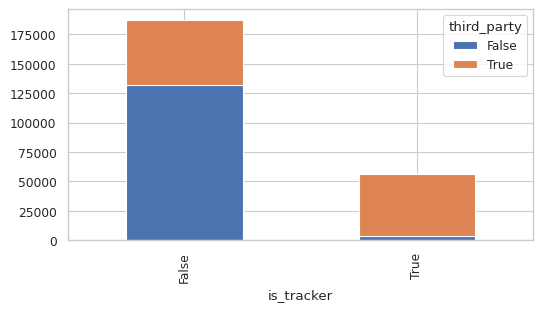

In [2]:
pd.crosstab(df['is_tracker'], df['third_party']).plot(kind='bar', stacked=True, figsize=(6, 3))


### First-party requests labeled as trackers
- A number of first-party requests are also detected as trackers (e.g. due to parameters and first-party tracking).
- First-party trackers (e.g. SST endpoints) can be included or excluded in aggregate stats depending on the analysis goal.

In [3]:
# first party requests detected as trackers
df[df.is_tracker & ~df.third_party].\
    drop_duplicates(subset=['site_hostname', 'req_hostname'])[
        ['site_hostname', 'req_hostname', 'url']].head(10)

,site_hostname,req_hostname,url
4373,www.soin-et-nature.com,care.soin-et-nature.com,https://care.soin-et-nature.com/g/collect?v=2&tid=G-LVK39FDZXP&gtm=45je4a90v873050401z879123941za200zb79123941&_p=1728894222...
11495,okfarma.es,okfarma.es,https://okfarma.es/modules/probance_track//views/js/probance_tracker-min.js
16635,www.farmaciabarata.es,www.farmaciabarata.es,https://www.farmaciabarata.es/cdn-cgi/rum?
17141,farmaciasenante.com,farmaciasenante.com,https://farmaciasenante.com/modules/mergado/views/js/gtag.js
21097,www.farmaciasdirect.es,www.farmaciasdirect.es,https://www.farmaciasdirect.es/cdn/shopifycloud/shopify/assets/shop_events_listener-61fa9e0a912c675e178777d2b27f6cbd482f8912...
21148,www.farmaciasdirect.es,datos.farmaciasdirect.es,https://datos.farmaciasdirect.es/g/collect?v=2&tid=G-GJ1M1YC9XE&gtm=45je4a90v869362756z89170334763za200zb9170334763&_p=17289...
24943,www.medpex.de,measure.medpex.de,https://measure.medpex.de/g/collect?v=2&tid=G-WETRC728CM&gtm=45je4a90v894411293z872399743za200zb72399743&_p=1729014480493&gc...
25950,www.aponeo.de,tmsst.aponeo.de,https://tmsst.aponeo.de/gtm.js?id=GTM-5GNVZ2M
27376,www.medikamente-per-klick.de,e.medikamente-per-klick.de,https://e.medikamente-per-klick.de/api/v6/tracking/webEvents
28968,www.shop-apotheke.com,klpoz.shop-apotheke.com,https://klpoz.shop-apotheke.com/g/collect?v=2&tid=G-102RDDVWR0&gtm=45je4a90v9100851417z8810479810za200zb810479810&_p=1728808...


### Tracker categories (purposes)
- Categories based on [Tracker Radar Dataset](https://github.com/duckduckgo/tracker-radar)

<Axes: ylabel='categories'>

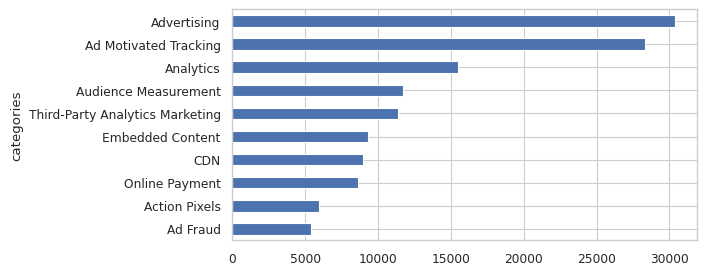

In [5]:
df[df.is_tracker].explode('categories')['categories'].\
    value_counts(ascending=True).tail(10).plot(kind='barh', figsize=(6, 3))

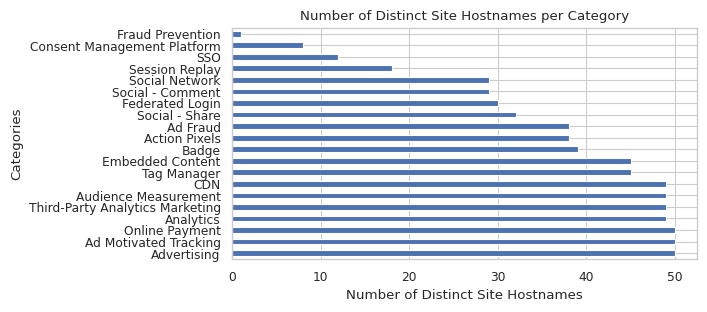

In [6]:
df[(df.exp_mode == 'tracking') & df.is_tracker].\
    explode('categories').groupby('categories')['site_hostname'].nunique().\
        sort_values(ascending=False).plot(kind='barh', figsize=(6, 3))
plt.xlabel('Number of Distinct Site Hostnames')
plt.ylabel('Categories')
plt.title('Number of Distinct Site Hostnames per Category')
plt.show()

### Tracker domains

In [9]:
tracker_domains = sorted(df[df.is_tracker].req_domain.unique().tolist())
len(tracker_domains), tracker_domains[:10]


(235,
 ['1rx.io',
  '360yield.com',
  '3lift.com',
  'abtasty.com',
  'acsbapp.com',
  'ad-srv.net',
  'adbr.io',
  'adcell.com',
  'addthis.com',
  'adform.net'])

### Median number of third-party domains per site

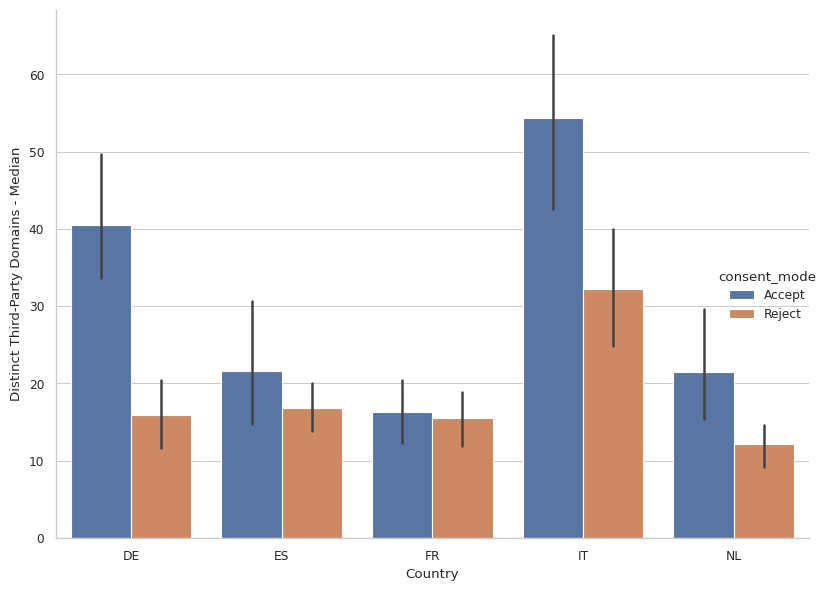

In [10]:

GROUP_COLS = ['exp_mode', 'consent_mode', 'country', 'site_domain']

df_median = df[df.third_party].groupby(GROUP_COLS)['req_domain'] \
                   .nunique() \
                   .groupby(GROUP_COLS) \
                   .median() \
                   .reset_index(name='median_req_domains')

# Convert the 'median_req_domains' column to integers
df_median['median_req_domains'] = df_median['median_req_domains'].astype(int)

df_median_t = df_median[df_median.exp_mode == 'tracking']
df_median_s = df_median[df_median.exp_mode == 'social']

sns.catplot(data=df_median_t, x='country', y='median_req_domains',
            hue='consent_mode', kind='bar', height=6, aspect=1.2)

# Add labels and title
# plt.title('Median Distinct Third-party Domains by Country and Consent Mode')
plt.ylabel('Distinct Third-Party Domains - Median')
plt.xlabel('Country')
# plt.legend(title='Consent Mode')

# Show the plot
plt.tight_layout()
plt.show()


### Median number of third-party domains per site (Social data)

Text(0.5, 27.40000000000002, 'Country')

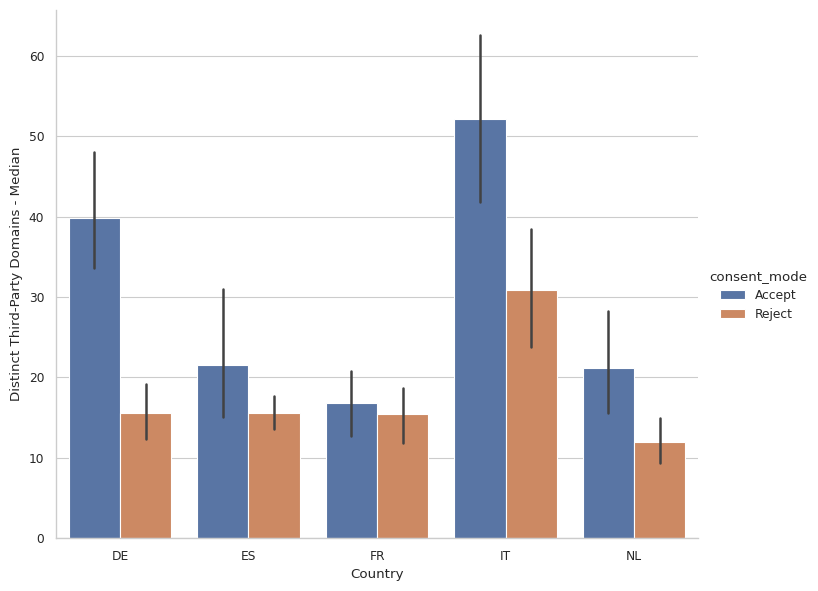

In [12]:
# Note: data from the social exp.
sns.catplot(data=df_median_s, x='country', y='median_req_domains',
            hue='consent_mode', kind='bar', height=6, aspect=1.2)

plt.ylabel('Distinct Third-Party Domains - Median')
plt.xlabel('Country')


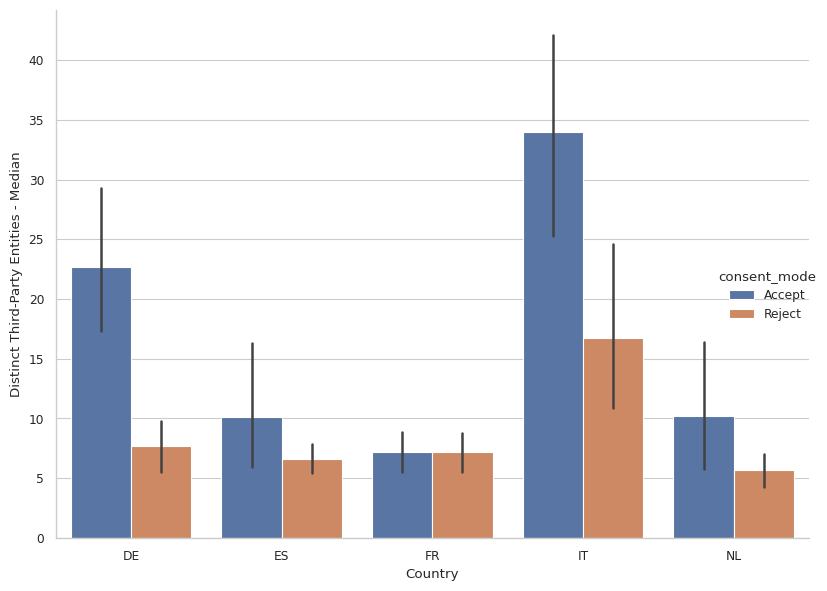

In [13]:

GROUP_COLS = ['exp_mode', 'consent_mode', 'country', 'site_domain']

df_median = df[df.third_party].groupby(GROUP_COLS)['entity'] \
                   .nunique() \
                   .groupby(GROUP_COLS) \
                   .median() \
                   .reset_index(name='median_entities')

# Convert the 'median_req_domains' column to integers
df_median['median_entities'] = df_median['median_entities'].astype(int)

df_median_t = df_median[df_median.exp_mode == 'tracking']
df_median_s = df_median[df_median.exp_mode == 'social']

sns.catplot(data=df_median_t, x='country', y='median_entities',
            hue='consent_mode', kind='bar', height=6, aspect=1.2)

# Add labels and title
# plt.title('Median Distinct Third-party Domains by Country and Consent Mode')
plt.ylabel('Distinct Third-Party Entities - Median')
plt.xlabel('Country')
# plt.legend(title='Consent Mode')

# Show the plot
plt.tight_layout()
plt.show()


## Focus on "Tracking" experiment

In [14]:
df_t = df[df['exp_mode'] == 'tracking']

### Number of third-party domains per site

In [15]:
# distinct third-party req_domain's by consent_mode, exp_mode, country, site_domain
df_t[df_t.third_party].\
    groupby(['consent_mode', 'country', 'site_domain'])['req_domain'].\
    nunique().to_frame()

req_domain
consent_mode country site_domain                         
Accept       DE      apodiscounter.de                  38
                     aponeo.de                         35
                     apotal.de                         25
                     docmorris.de                      41
                     medikamente-per-klick.de          40
...                                                   ...
Reject       NL      gezondheidaanhuis.nl              12
                     koopjesdrogisterij.nl             11
                     kruidvat.nl                       12
                     plein.nl                          19
                     trekpleister.nl                    7

[100 rows x 1 columns]

### Number of third-party entities per site

In [16]:
# distinct third-party req_domain's by consent_mode, exp_mode, country, site_domain
df_t[df_t.third_party].\
    groupby(['consent_mode', 'country', 'site_domain'])['entity'].\
    nunique().to_frame()

entity
consent_mode country site_domain                     
Accept       DE      apodiscounter.de              16
                     aponeo.de                     19
                     apotal.de                     13
                     docmorris.de                  21
                     medikamente-per-klick.de      18
...                                               ...
Reject       NL      gezondheidaanhuis.nl           6
                     koopjesdrogisterij.nl          4
                     kruidvat.nl                    7
                     plein.nl                       8
                     trekpleister.nl                5

[100 rows x 1 columns]

### Accept vs Reject - Top 10 third-party domains

In [17]:

tmp_df = df_t.pivot_table(
    index='req_domain',                  # Rows: Unique request domains
    columns='consent_mode',           # Columns: Consent mode (accepted/rejected)
    values='site_domain',                # Values: Count of unique site domains
    aggfunc='nunique',                   # Aggregate function: Count unique site domains
    fill_value=0                          # Fill missing values with 0
)

tmp_df.sort_values(by='Accept', ascending=False).head(10)

consent_mode,Accept,Reject
req_domain,,
google.com,50,42
doubleclick.net,48,22
googletagmanager.com,45,40
gstatic.com,44,46
google-analytics.com,35,24
bing.com,34,13
facebook.com,31,11
facebook.net,27,10
fonts.googleapis.com,25,27


### Accept vs Reject - Top 10 third-party entities

In [20]:

table = df_t[df_t.entity != ''].pivot_table(
    index='entity',                  # Rows: Unique entity names
    columns='consent_mode',           # Columns: Consent mode (accepted/rejected)
    values='site_domain',                # Values: Count of unique site domains
    aggfunc='nunique',                   # Aggregate function: Count unique site domains
    fill_value=0                          # Fill missing values with 0
)

# Optionally sort the results if needed
table.sort_values(by='Accept', ascending=False).head(12)

consent_mode,Accept,Reject
entity,,
Google,50,48
Microsoft,36,16
Facebook,32,13
Virtual Minds,18,7
Criteo,16,3
ID5,16,2
PayPal,15,15
Trusted Shops,14,12
IPONWEB,13,3


### Close look on site with most third-party domains

In [19]:
df_t[df_t.site_domain == 'sanicare.de']['entity'].unique()

array(['', 'Usercentrics', 'Trusted Shops', 'SAP', 'Google', 'Trbo',
       'Microsoft', 'Awin', 'Criteo', 'Facebook', 'Virtual Minds',
       'advanced STORE', 'IPONWEB', 'Smartadserver', 'Taboola',
       'Adyoulike', 'Index Exchange', 'ID5', 'Improve Digital',
       'Ividence', 'Media.net Advertising', 'Mediavine', 'Nativo',
       'Outbrain', 'PubMatic', 'Magnite', 'Sharethrough', 'Teads',
       'Telaria', 'TripleLift', 'YieldMo', 'Engine USA', 'RhythmOne',
       'SMARTSTREAM.TV', 'Sirius XM', 'Online Solution Int', 'Adobe',
       'KUPONA', 'Unruly Group', 'Ströer Group', 'twiago', 'MediaMath',
       'Adform', 'Flashtalking', 'The Trade Desk', 'Amazon.com'],
      dtype=object)